<a href="https://colab.research.google.com/github/Kadidjah/InteligenciaArtifical_LinguagensFormais_Automatos/blob/main/Aprendizado_Maquina_Introducao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Introdução
## Sistema especialista com aprendizado supervisionado
**Profa. Kadidja Valéria**

**Inteligência Artificial e LFA | Sistemas Especialistas**

Execute este notebook no **Google Colab** ou no Jupyter, de cima para baixo. No Colab: Arquivo > Fazer upload de notebook > selecione este arquivo.

**Objetivo:** treinar um classificador e usar sua previsão como fato em um sistema especialista que recomenda atividades de estudo.

**Leitura:** [Guia IBM](https://www.ibm.com/br-pt/think/machine-learning) e [aprendizado supervisionado](https://www.ibm.com/br-pt/think/topics/supervised-learning).

Responda: o que é aprendizado de máquina? O que são atributos e rótulos? Como classificação difere de regressão? Por que separar treino e teste?

Os dados abaixo são fictícios, muito pequenos e deliberadamente simples. Este exemplo não valida uma ferramenta de avaliação de estudantes reais.

## 1. Preparar o ambiente
No Colab, as bibliotecas geralmente já estão disponíveis. Se o próximo bloco apresentar `ModuleNotFoundError`, execute em uma nova célula: `%pip install pandas scikit-learn matplotlib` e tente novamente.

In [1]:
# Importação das bibliotecas necessárias
# pandas: manipulação e análise de dados estruturados
import pandas as pd
# matplotlib.pyplot: geração de gráficos e visualizações
import matplotlib.pyplot as plt
# train_test_split: divisão do dataset em conjuntos de treino e teste
from sklearn.model_selection import train_test_split
# DecisionTreeClassifier: o algoritmo de árvore de decisão para classificação
# export_text e plot_tree: ferramentas para visualizar as regras aprendidas pela árvore
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# Métricas para avaliação do modelo: acurácia e matriz de confusão
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Confirmação de que as dependências foram carregadas com sucesso
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado
Cada linha é um exemplo. As entradas são horas de estudo semanal e percentual de exercícios concluídos. O rótulo `perfil` é a resposta conhecida: `apoio` ou `autonomia`. Aqui os rótulos foram atribuídos manualmente para uma demonstração. Em um projeto real, documente quem rotulou os exemplos, com quais critérios e evidências.

In [2]:
# Criação do DataFrame fictício com os dados dos estudantes
# Atributos (características): horas_estudo e exercicios_percentual
# Rótulo (classe alvo): perfil (apoio ou autonomia)
dados = pd.DataFrame({
    "horas_estudo": [1,2,2,3,3,4,1,4,5,6,7,8,5,6,7,8],
    "exercicios_percentual": [10,20,30,35,40,45,15,50,
                              65,75,85,95,70,80,90,100],
    "perfil": ["apoio"] * 8 + ["autonomia"] * 8
})

# Exibição do dataset completo estruturado
print(dados.to_string(index=False))

# Exibição da distribuição de classes para verificar se o dataset está balanceado
print("\nQuantidade por classe:")
print(dados["perfil"].value_counts())

 horas_estudo  exercicios_percentual    perfil
            1                     10     apoio
            2                     20     apoio
            2                     30     apoio
            3                     35     apoio
            3                     40     apoio
            4                     45     apoio
            1                     15     apoio
            4                     50     apoio
            5                     65 autonomia
            6                     75 autonomia
            7                     85 autonomia
            8                     95 autonomia
            5                     70 autonomia
            6                     80 autonomia
            7                     90 autonomia
            8                    100 autonomia

Quantidade por classe:
perfil
apoio        8
autonomia    8
Name: count, dtype: int64


## 3. Separar treinamento e teste
`X` contém atributos e `y` contém o rótulo. Reservamos 25% dos exemplos para teste: são 12 exemplos de treino e 4 de teste. `stratify` preserva a proporção das classes; `random_state` torna a divisão reproduzível. O rótulo nunca entra em `X`.

In [3]:
# Separação das variáveis explicativas/atributos (X) e a variável resposta/rótulo (y)
X = dados[["horas_estudo", "exercicios_percentual"]]
y = dados["perfil"]

# Divisão do dataset: 75% para treinamento e 25% para teste
# stratify=y garante que a proporção das classes se mantenha igual nos dois conjuntos
# random_state=42 garante a reprodutibilidade dos resultados
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Impressão do tamanho das amostras de treino e de teste
print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 12 | Teste: 4


## 4. Treinar e avaliar
`fit` aprende padrões somente no treino; `predict` gera previsões. Acurácia é a fração de acertos no teste. Na matriz, linhas são classes reais e colunas são previstas. Não ajuste o modelo repetidamente para acertar este mesmo teste: use validação separada se fizer ajustes.

Acurácia no teste: 100.0%
           apoio  autonomia
apoio          2          0
autonomia      0          2


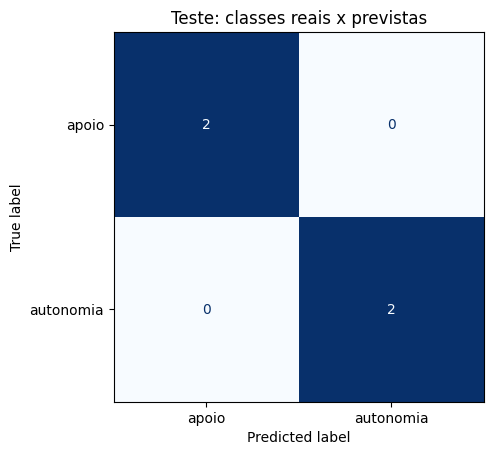

Condições aprendidas:
|--- horas_estudo <= 4.50
|   |--- class: apoio
|--- horas_estudo >  4.50
|   |--- class: autonomia



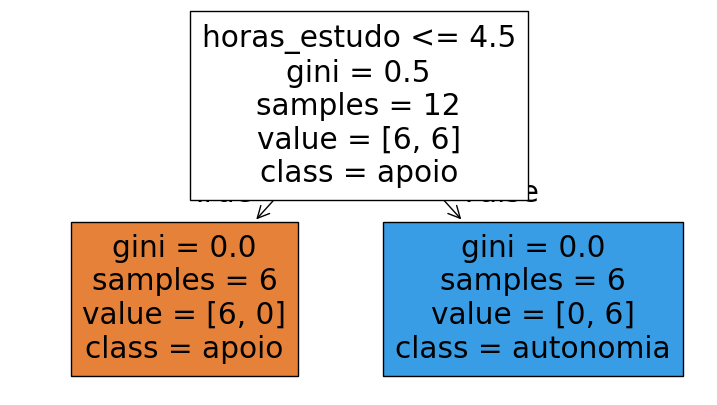

In [4]:
# Inicialização do classificador de Árvore de Decisão limitando a profundidade a 2
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)

# Treinamento do modelo usando o conjunto de treino (ajuste aos dados)
modelo.fit(X_treino, y_treino)

# Geração de previsões utilizando os atributos do conjunto de teste
previsoes = modelo.predict(X_teste)

# Cálculo e exibição da acurácia do modelo no conjunto de teste
print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

# Definição das classes para ordenação da matriz de confusão
classes = ["apoio", "autonomia"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)

# Exibição da matriz de confusão formatada em formato textual (DataFrame)
print(pd.DataFrame(matriz, index=classes, columns=classes))

# Geração e exibição gráfica da Matriz de Confusão
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(
    cmap="Blues", colorbar=False
)
plt.title("Teste: classes reais x previstas")
plt.show()

# Exibição das regras lógicas aprendidas pela árvore de decisão em formato texto
print("Condições aprendidas:")
print(export_text(modelo, feature_names=list(X.columns)))

# Plotagem e exibição gráfica detalhada da estrutura da árvore de decisão
plt.figure(figsize=(9, 5))
plot_tree(modelo, feature_names=list(X.columns),
          class_names=list(modelo.classes_), filled=True)
plt.show()

### Entendendo os Termos da Árvore de Decisão

Cada nó (caixa) na visualização da árvore de decisão contém três métricas fundamentais que explicam como o algoritmo tomou suas decisões:

1. **Gini (Índice Gini):**
   * Mede a **impureza** ou mistura dos dados naquele nó. Varia de `0.0` (pureza total) a `0.5` (mistura máxima para duas classes).
   * **`gini = 0.0` (Nós Folhas):** Significa que todos os exemplos que chegaram ali pertencem a uma única classe (estão perfeitamente separados).
   * **`gini = 0.5` (Nó Raiz):** Significa que os dados estão completamente divididos meio a meio (50% de cada perfil).

2. **Samples (Amostras):**
   * Indica o **número de estudantes** (amostras) do conjunto de treino analisados naquele nó.
   * O nó inicial (raiz) começa com `12` amostras. Após a regra de divisão (`horas_estudo <= 4.5`), cada nó filho passa a conter `6` amostras.

3. **Value (Valores por classe):**
   * Mostra a **distribuição exata** de estudantes em cada classe no formato `[quantidade_classe_1, quantidade_classe_2]`, seguindo a ordem alfabética das classes target (`[apoio, autonomia]`).
   * No início (`value = [6, 6]`), temos 6 estudantes de perfil *apoio* e 6 de *autonomia*.
   * No nó folha da esquerda (`value = [6, 0]`), todas as 6 amostras pertencem ao perfil *apoio*.

**Interpretação:** como as classes foram construídas com separação simples e existem apenas quatro casos de teste, mesmo 100% de acurácia não demonstra eficácia em situações reais. A árvore mostra condições aprendidas; as regras de recomendação abaixo foram escritas por pessoas.

## 5. Base de conhecimento e motor de inferência
A previsão vira um fato. Outro fato, informado pelo usuário, é a dificuldade em lógica. O motor procura a regra compatível e apresenta recomendação e justificativa.

In [5]:
# Definição da Base de Conhecimento do sistema especialista contendo as regras de negócio
regras = [
    {"id": "R1", "perfil": "apoio", "dificuldade_logica": True,
     "acao": "Participar de monitoria de lógica."},
    {"id": "R2", "perfil": "apoio", "dificuldade_logica": False,
     "acao": "Realizar revisão guiada e exercícios básicos."},
    {"id": "R3", "perfil": "autonomia", "dificuldade_logica": True,
     "acao": "Resolver exercícios específicos de lógica."},
    {"id": "R4", "perfil": "autonomia", "dificuldade_logica": False,
     "acao": "Desenvolver um pequeno projeto prático."}
]

# Motor de Inferência: Função que recebe os fatos e busca uma regra correspondente na base
def aplicar_regras(perfil, dificuldade_logica):
    for regra in regras:
        # Verifica se as condições da regra coincidem com os fatos fornecidos
        if (regra["perfil"] == perfil and
            regra["dificuldade_logica"] == dificuldade_logica):
            return {
                "perfil_previsto": perfil,
                "regra": regra["id"],
                "recomendacao": regra["acao"],
                "explicacao": (
                    f"Perfil previsto: {perfil}; dificuldade em lógica: "
                    f"{dificuldade_logica}."
                )
            }
    # Lança erro se nenhuma regra cobrir a combinação de fatos de entrada
    raise ValueError("Nenhuma regra compatível com os fatos.")

## 6. Integrar o modelo ao sistema especialista
A função valida os valores, realiza a previsão e aplica as regras. Valores fora dos intervalos observados no treino recebem um aviso, pois a previsão pode ser menos confiável.

In [6]:
# Integração: Função que unifica o modelo de Machine Learning e o Sistema Especialista
def orientar_estudante(horas, percentual, dificuldade_logica):
    # Validações dos dados de entrada para garantir limites lógicos consistentes
    if not 0 <= horas <= 168:
        raise ValueError("Horas semanais devem estar entre 0 e 168.")
    if not 0 <= percentual <= 100:
        raise ValueError("Percentual deve estar entre 0 e 100.")
    if not isinstance(dificuldade_logica, bool):
        raise ValueError("Dificuldade em lógica deve ser True ou False.")

    # Criação de um novo DataFrame para alimentar o modelo treinado
    novo_caso = pd.DataFrame([{
        "horas_estudo": horas,
        "exercicios_percentual": percentual
    }])

    # 1. Classificação: Predição do perfil do aluno pelo modelo de Árvore de Decisão
    perfil = modelo.predict(novo_caso)[0]

    # 2. Inferência: Aplicação das regras do sistema especialista com base na predição e na lógica
    resultado = aplicar_regras(perfil, dificuldade_logica)

    # Verificação opcional se o novo exemplo está fora do intervalo do conjunto de treino
    fora = any(
        not X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max()
        for c in X.columns
    )

    # Adição de um aviso sobre a confiabilidade do resultado gerado
    resultado["aviso"] = (
        "Entrada fora dos intervalos observados no treino."
        if fora else "Exemplo didático; orientação sujeita a revisão humana."
    )
    return resultado

# Definição de novos casos de teste práticos (não vistos no treinamento do modelo)
casos = [(2, 25, True), (6, 82, False), (3, 38, False)]

# Loop para iterar, classificar e aplicar as regras a cada um dos casos novos
for i, (horas, percentual, dificuldade) in enumerate(casos, 1):
    print(f"\nCASO {i}: {horas} h; {percentual}%; lógica={dificuldade}")
    for campo, valor in orientar_estudante(
        horas, percentual, dificuldade
    ).items():
        print(f"{campo}: {valor}")


CASO 1: 2 h; 25%; lógica=True
perfil_previsto: apoio
regra: R1
recomendacao: Participar de monitoria de lógica.
explicacao: Perfil previsto: apoio; dificuldade em lógica: True.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 2: 6 h; 82%; lógica=False
perfil_previsto: autonomia
regra: R4
recomendacao: Desenvolver um pequeno projeto prático.
explicacao: Perfil previsto: autonomia; dificuldade em lógica: False.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 3: 3 h; 38%; lógica=False
perfil_previsto: apoio
regra: R2
recomendacao: Realizar revisão guiada e exercícios básicos.
explicacao: Perfil previsto: apoio; dificuldade em lógica: False.
aviso: Exemplo didático; orientação sujeita a revisão humana.


## 7. Experimente uma consulta
Altere os três valores abaixo e execute novamente. Compare casos com a mesma previsão e diferentes respostas sobre dificuldade em lógica. Qual componente modifica a recomendação?

In [7]:
# Definição das variáveis de entrada para uma consulta simulada e interativa
horas = 2
percentual = 25
dificuldade_logica = True

# Execução da consulta chamando a função integradora do sistema
resultado = orientar_estudante(horas, percentual, dificuldade_logica)

# Exibição detalhada de cada atributo retornado pelo motor de inferência
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

perfil_previsto: apoio
regra: R1
recomendacao: Participar de monitoria de lógica.
explicacao: Perfil previsto: apoio; dificuldade em lógica: True.
aviso: Exemplo didático; orientação sujeita a revisão humana.


## 8. Atividade e entrega
1. Escolha um problema e defina entradas, rótulo e recomendação.
2. Escreva pelo menos quatro regras e justifique sua origem.
3. Prepare um dataset rotulado; informe tamanho, origem e critérios de rotulagem. Identifique dados simulados.
4. Separe treino e teste, treine um classificador e apresente acurácia e matriz de confusão.
5. Use a previsão em pelo menos uma regra do sistema especialista.
6. Demonstre três novos casos com previsão, regra aplicada e explicação.
7. Discuta erros, limitações, exemplos pouco representados e cuidados com dados pessoais.

**Entregue:** notebook comentado, dataset, respostas à leitura e análise dos resultados. Adapte o exemplo ao seu problema; não apenas altere o título.

## Referências
- IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
- IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
- scikit-learn. DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
